In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import gc
import io
import json
import time
import zipfile
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import requests
import torch
import torch.nn.functional as F
import transformers
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm
from transformers import AutoModel, AutoProcessor

In [3]:
ROOT = Path("/content/drive/MyDrive/MLLM")
DATA = ROOT / "data"
IMAGES = DATA / "images"
OUTPUTS = ROOT / "outputs"

for folder in (DATA, IMAGES, OUTPUTS):
    folder.mkdir(parents=True, exist_ok=True)

CLIP_ID = "openai/clip-vit-base-patch16"
SIGLIP_ID = "google/siglip2-base-patch16-224"
device = "cuda" if torch.cuda.is_available() else "cpu"

clip_en = torch.load(
    OUTPUTS / "clip_en_subset500.pt",
    map_location="cpu",
    weights_only=True,
)

image_ids = clip_en["image_ids"]
print("Device:", device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("Transformers:", transformers.__version__)
print("Saved baseline:", clip_en["image_embeddings"].shape)

Device: cuda
GPU: Tesla T4
Transformers: 5.18.0
Saved baseline: torch.Size([500, 512])


In [4]:
manifest_path = DATA / "xm3600_subset500.json"

if not manifest_path.exists():
    response = requests.get(
        "https://google.github.io/crossmodal-3600/web-data/captions.zip",
        timeout=60,
    )
    response.raise_for_status()

    needed = set(image_ids)
    selected = {}

    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        with archive.open("captions.jsonl") as source:
            for line in source:
                item = json.loads(line)
                image_id = item["image/key"]

                if image_id in needed:
                    selected[image_id] = {
                        "image_id": image_id,
                        "en": item["en"]["caption"],
                        "bn": item["bn"]["caption"],
                    }

    subset = [selected[image_id] for image_id in image_ids]

    temporary = manifest_path.with_suffix(".json.part")
    temporary.write_text(
        json.dumps(subset, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    temporary.replace(manifest_path)

by_id = {
    item["image_id"]: item
    for item in json.loads(manifest_path.read_text(encoding="utf-8"))
}

subset = [by_id[image_id] for image_id in image_ids]

records = {
    language: [
        {
            "image_id": item["image_id"],
            "caption_index": j,
            "text": caption,
        }
        for item in subset
        for j, caption in enumerate(item[language])
    ]
    for language in ("en", "bn")
}

assert records["en"] == clip_en["caption_records"]

for language in ("en", "bn"):
    print(language, "captions:", len(records[language]))

en captions: 1000
bn captions: 500


In [5]:
def ensure_image(image_id):
    path = IMAGES / f"{image_id}.jpg"

    if path.exists():
        return

    response = requests.get(
        "https://open-images-dataset.s3.amazonaws.com/"
        f"crossmodal-3600/{image_id}.jpg",
        timeout=(15, 60),
    )
    response.raise_for_status()

    with Image.open(io.BytesIO(response.content)) as image:
        image.verify()

    temporary = path.with_suffix(".jpg.part")
    temporary.write_bytes(response.content)
    temporary.replace(path)


missing = [
    image_id for image_id in image_ids
    if not (IMAGES / f"{image_id}.jpg").exists()
]

with ThreadPoolExecutor(max_workers=4) as executor:
    for _ in tqdm(
        executor.map(ensure_image, missing),
        total=len(missing),
        desc="Missing images",
    ):
        pass


def load_rgb(image_id):
    with Image.open(IMAGES / f"{image_id}.jpg") as image:
        return image.convert("RGB")


print("Images ready:", len(image_ids))

Missing images:   0%|          | 0/500 [00:00<?, ?it/s]

Images ready: 500


**Encoding and cache helpers**

In [6]:
TOKEN_LIMITS = {"CLIP": 77, "SigLIP2": 64}


def prepare_texts(texts, family):
    return [text.lower() for text in texts] if family == "SigLIP2" else texts


def make_inputs(processor, family, kind, items):
    if kind == "image":
        inputs = processor(
            images=[load_rgb(image_id) for image_id in items],
            return_tensors="pt",
        )
    else:
        inputs = processor(
            text=prepare_texts(items, family),
            padding="max_length" if family == "SigLIP2" else True,
            truncation=True,
            max_length=TOKEN_LIMITS[family],
            return_tensors="pt"
        )

    return inputs.to(device)


def feature_tensor(result):
    return result if isinstance(result, torch.Tensor) else result.pooler_output


@torch.inference_mode()
def encode(model, processor, family, kind, items, batch_size):
    chunks = []
    encoder = getattr(model, f"get_{kind}_features")

    for start in tqdm(
        range(0, len(items), batch_size),
        desc=f"{family} {kind}",
    ):
        inputs = make_inputs(
            processor, family, kind,
            items[start:start + batch_size],
        )

        result = encoder(**inputs, return_dict=True)
        features = feature_tensor(result).float()

        chunks.append(F.normalize(features, dim=-1).cpu())

    return torch.cat(chunks)


def save_cache(family, language, model_id, processor, image_features, text_features):
    texts = [record["text"] for record in records[language]]

    token_ids = processor.tokenizer(
        prepare_texts(texts, family),
        truncation=False,
        padding=False,
        verbose=False,
    )["input_ids"]

    cache = {
        "model_id": model_id,
        "language": language,
        "image_ids": image_ids,
        "caption_records": records[language],
        "image_embeddings": image_features,
        "text_embeddings": text_features,
        "max_tokens": TOKEN_LIMITS[family],
        "truncated_caption_count": sum(
            len(ids) > TOKEN_LIMITS[family] for ids in token_ids
        ),
        "torch_version": str(torch.__version__),
        "transformers_version": str(transformers.__version__),
    }

    prefix = "clip" if family == "CLIP" else "siglip2"
    path = OUTPUTS / f"{prefix}_{language}_subset500.pt"
    temporary = path.with_suffix(".pt.part")

    torch.save(cache, temporary)
    temporary.replace(path)

    print(f"{family}/{language}:", text_features.shape)
    return cache

**Timing helper**

In [7]:
@torch.inference_mode()
def benchmark(model, processor, family, kind, items):
    inputs = make_inputs(processor, family, kind, items)
    encoder = getattr(model, f"get_{kind}_features")

    encoder(**inputs, return_dict=True)
    elapsed = []

    for _ in range(3):
        if device == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()
        encoder(**inputs, return_dict=True)

        if device == "cuda":
            torch.cuda.synchronize()

        elapsed.append(time.perf_counter() - start)

    return 1000 * np.mean(elapsed) / len(items)


timing_rows = []

def record_timing(model, processor, family):
    image_ms = benchmark(
        model, processor, family, "image", image_ids[:16]
    )

    for language in ("en", "bn"):
        texts = [record["text"] for record in records[language]][:64]

        timing_rows.append({
            "model": family,
            "language": language,
            "image_batch": 16,
            "text_batch": len(texts),
            "image_ms_per_item": image_ms,
            "text_ms_per_item": benchmark(
                model, processor, family, "text", texts
            ),
        })

**CLIP**

In [8]:
caches = {("CLIP", "en"): clip_en}

processor = AutoProcessor.from_pretrained(CLIP_ID)
model = AutoModel.from_pretrained(CLIP_ID).float().to(device).eval()

bn_texts = [record["text"] for record in records["bn"]]

clip_bn_features = encode(
    model, processor, "CLIP", "text", bn_texts, batch_size=64
)

caches[("CLIP", "bn")] = save_cache(
    "CLIP", "bn", CLIP_ID, processor,
    clip_en["image_embeddings"],
    clip_bn_features,
)

record_timing(model, processor, "CLIP")

del model, processor
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP text:   0%|          | 0/8 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

model.safetensors: downloading bytes:           |  0.00B            

CLIP/bn: torch.Size([500, 512])


In [9]:
processor = AutoProcessor.from_pretrained(SIGLIP_ID)
model = AutoModel.from_pretrained(SIGLIP_ID).float().to(device).eval()

siglip_image_features = encode(
    model, processor, "SigLIP2", "image",
    image_ids, batch_size=16,
)

print("SigLIP2 image embeddings:", siglip_image_features.shape)

for language in ("en", "bn"):
    texts = [record["text"] for record in records[language]]

    text_features = encode(
        model, processor, "SigLIP2", "text",
        texts, batch_size=64,
    )

    caches[("SigLIP2", language)] = save_cache(
        "SigLIP2", language, SIGLIP_ID, processor,
        siglip_image_features,
        text_features,
    )

record_timing(model, processor, "SigLIP2")

del model, processor
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()

preprocessor_config.json:   0%|          | 0.00/394 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/253 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


tokenizer_config.json:   0%|          | 0.00/47.2k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 34.4MB            

...

SigLIP2 image embeddings: torch.Size([500, 768])


SigLIP2 text:   0%|          | 0/16 [00:00<?, ?it/s]

SigLIP2/en: torch.Size([1000, 768])


SigLIP2 text:   0%|          | 0/8 [00:00<?, ?it/s]

SigLIP2/bn: torch.Size([500, 768])


**Metrics, truncation and timing tables**

In [10]:
def recall_at_k(scores, query_ids, candidate_ids, ks=(1, 5, 10)):
    query_ids = np.asarray(query_ids)
    candidate_ids = np.asarray(candidate_ids)

    assert scores.shape == (len(query_ids), len(candidate_ids))
    assert np.isfinite(scores).all()
    assert np.isin(query_ids, candidate_ids).all()

    ranked = np.argsort(
        -scores, axis=1, kind="stable"
    )[:, :max(ks)]

    matches = candidate_ids[ranked] == query_ids[:, None]

    return {
        f"R@{k}": 100 * matches[:, :k].any(axis=1).mean()
        for k in ks
    }


metric_rows = []
token_rows = []
similarities = {}

for (family, language), cache in caches.items():
    assert cache["image_ids"] == image_ids
    assert cache["caption_records"] == records[language]

    caption_ids = [
        record["image_id"] for record in cache["caption_records"]
    ]

    S = (cache["image_embeddings"] @ cache["text_embeddings"].T).numpy()
    similarities[(family, language)] = S

    for direction, scores, queries, candidates in [
        ("Image → Text", S, image_ids, caption_ids),
        ("Text → Image", S.T, caption_ids, image_ids),
    ]:
        metric_rows.append({
            "model": family,
            "language": language,
            "direction": direction,
            "queries": len(queries),
            "candidates": len(candidates),
            **recall_at_k(scores, queries, candidates),
        })

    token_rows.append({
        "model": family,
        "language": language,
        "captions": len(caption_ids),
        "token_limit": cache["max_tokens"],
        "truncated": cache["truncated_caption_count"],
    })

metrics_df = pd.DataFrame(metric_rows)
tokens_df = pd.DataFrame(token_rows)
timing_df = pd.DataFrame(timing_rows)

display(metrics_df.round(2))
display(tokens_df)
display(timing_df.round(3))

,model,language,direction,queries,candidates,R@1,R@5,R@10
0,CLIP,en,Image → Text,500,1000,79.8,95.2,98.2
1,CLIP,en,Text → Image,1000,500,66.7,88.5,93.2
2,CLIP,bn,Image → Text,500,500,0.2,1.2,2.0
3,CLIP,bn,Text → Image,500,500,0.2,1.2,2.2
4,SigLIP2,en,Image → Text,500,1000,85.4,98.0,99.4
5,SigLIP2,en,Text → Image,1000,500,79.4,95.8,98.8
6,SigLIP2,bn,Image → Text,500,500,19.6,39.4,47.0
7,SigLIP2,bn,Text → Image,500,500,12.2,25.8,35.0


,model,language,captions,token_limit,truncated
0,CLIP,en,1000,77,0
1,CLIP,bn,500,77,441
2,SigLIP2,en,1000,64,0
3,SigLIP2,bn,500,64,0


,model,language,image_batch,text_batch,image_ms_per_item,text_ms_per_item
0,CLIP,en,16,64,9.86,0.600
1,CLIP,bn,16,64,9.86,1.810
2,SigLIP2,en,16,64,10.44,2.899
3,SigLIP2,bn,16,64,10.44,2.877


Bangla query: অনেক ঘরবাড়ি ও গাছপালাময় এলাকার এরিয়াল দৃশ্য এবং দূরে নদী আছে


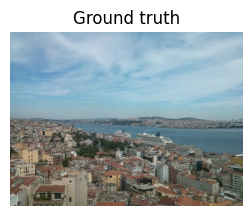

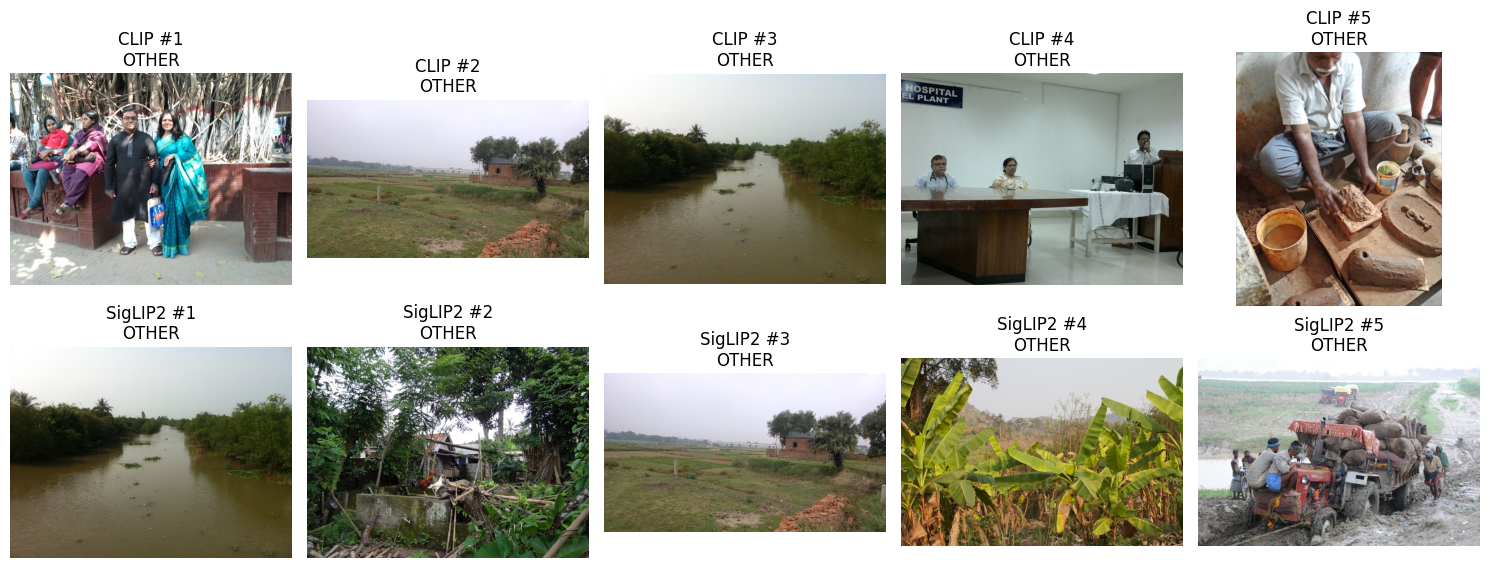

In [11]:
q = 0
query = records["bn"][q]

print("Bangla query:", query["text"])
plt.figure(figsize=(3, 3))
plt.imshow(load_rgb(query["image_id"]))
plt.title("Ground truth")
plt.axis("off")
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for row, family in enumerate(("CLIP", "SigLIP2")):
    S = similarities[(family, "bn")]
    top = np.argsort(-S[:, q], kind="stable")[:5]

    for rank, image_index in enumerate(top):
        correct = image_ids[image_index] == query["image_id"]

        axes[row, rank].imshow(load_rgb(image_ids[image_index]))
        axes[row, rank].set_title(
            f"{family} #{rank + 1}\n"
            f"{'MATCH' if correct else 'OTHER'}"
        )
        axes[row, rank].axis("off")

plt.tight_layout()
plt.show()

In [12]:
metrics_df.to_csv(OUTPUTS / "day3_retrieval_comparison.csv", index=False)
tokens_df.to_csv(OUTPUTS / "day3_token_truncation.csv", index=False)
timing_df.to_csv(OUTPUTS / "day3_encoder_timing.csv", index=False)

print("Saved to:", OUTPUTS)

Saved to: /content/drive/MyDrive/MLLM/outputs
